# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [2]:
# Use numba's own thread pool, not OpenMP: torch, scikit-learn and conda each ship a
# separate libomp, and numba's OpenMP layer segfaults the kernel on macOS when they collide.
import os
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"

import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: False
scanpy 1.11.5 | squidpy 1.8.2


/var/folders/t8/b8x5dzd135zgwb8p4127n5lw0000gn/T/ipykernel_20726/3097897553.py:21: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [3]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 1,101,430


/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/var/folders/t8/b8x5dzd135zgwb8p4127n5lw0000gn/T/ipykernel_20726/3322223012.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id",
                            span=0.5)  # wider loess span: two low-depth donors fail the fit at the default 0.3
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [5]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

malignant cells mislabeled as ['T'] : 8526
cell_type_broad
Epithelial/Tumor    8678
Other               2976
T                   2354
Endothelial         1431
Macrophage          1189
Fibroblast          1072
B                    529
Monocyte              73
NK                    50
DC                    36 

cells: 18388 | donors: 10
assays:
assay
10x 3' v3    12635
10x 3' v2     3753
10x 5' v2     2000


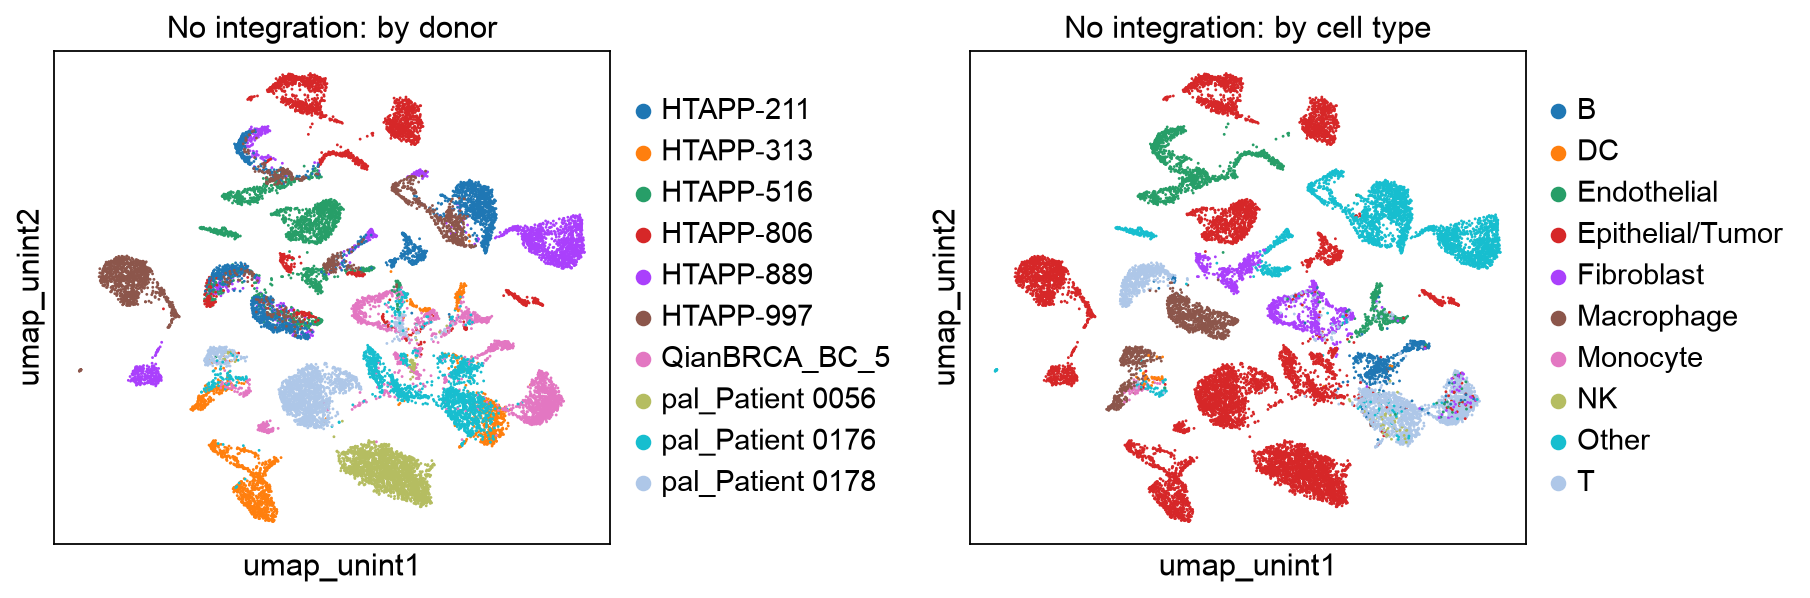

In [6]:
# TODO: plot the unintegrated UMAP colored by donor and by cell type.
# Label check before trusting the map: broad_type() tests for "t cell" before tumor words,
# and "malignant cell" contains the substring "t cell" ("malignan-t cell"), so the Census's
# malignant cells were all labeled T. Move them to Epithelial/Tumor.
is_malignant = adata.obs["cell_type"].astype(str).str.contains("malignant")
print("malignant cells mislabeled as", adata.obs.loc[is_malignant, "cell_type_broad"].unique().tolist(), ":", int(is_malignant.sum()))
adata.obs["cell_type_broad"] = adata.obs["cell_type_broad"].astype(str)
adata.obs.loc[is_malignant, "cell_type_broad"] = "Epithelial/Tumor"
adata.obs["cell_type_broad"] = adata.obs["cell_type_broad"].astype("category")
print(adata.obs["cell_type_broad"].value_counts().to_string(), "\n")

print("cells:", adata.n_obs, "| donors:", adata.obs["donor_id"].nunique())
print("assays:\n" + adata.obs["assay"].value_counts().to_string())
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5,
                title=["No integration: by donor", "No integration: by cell type"])

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

The data is organized by **donor**, not by biology. In the unintegrated map almost every island is a single donor color, and the same cell type is split across several donor-specific islands (each donor's tumor cells and T cells sit in their own groups). The positive batch silhouette (0.095, below) confirms that cells sit closer to their own donor than to other donors.

I also checked the labels before trusting them. The provided `broad_type()` labeled all 8,526 Census "malignant cell" cells as T, because "malignant cell" contains the substring "t cell". I moved them to Epithelial/Tumor at the top of the 1.3 cell, so every plot and score below uses the corrected labels.

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [7]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training:   0%|          | 0/60 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


scVI done


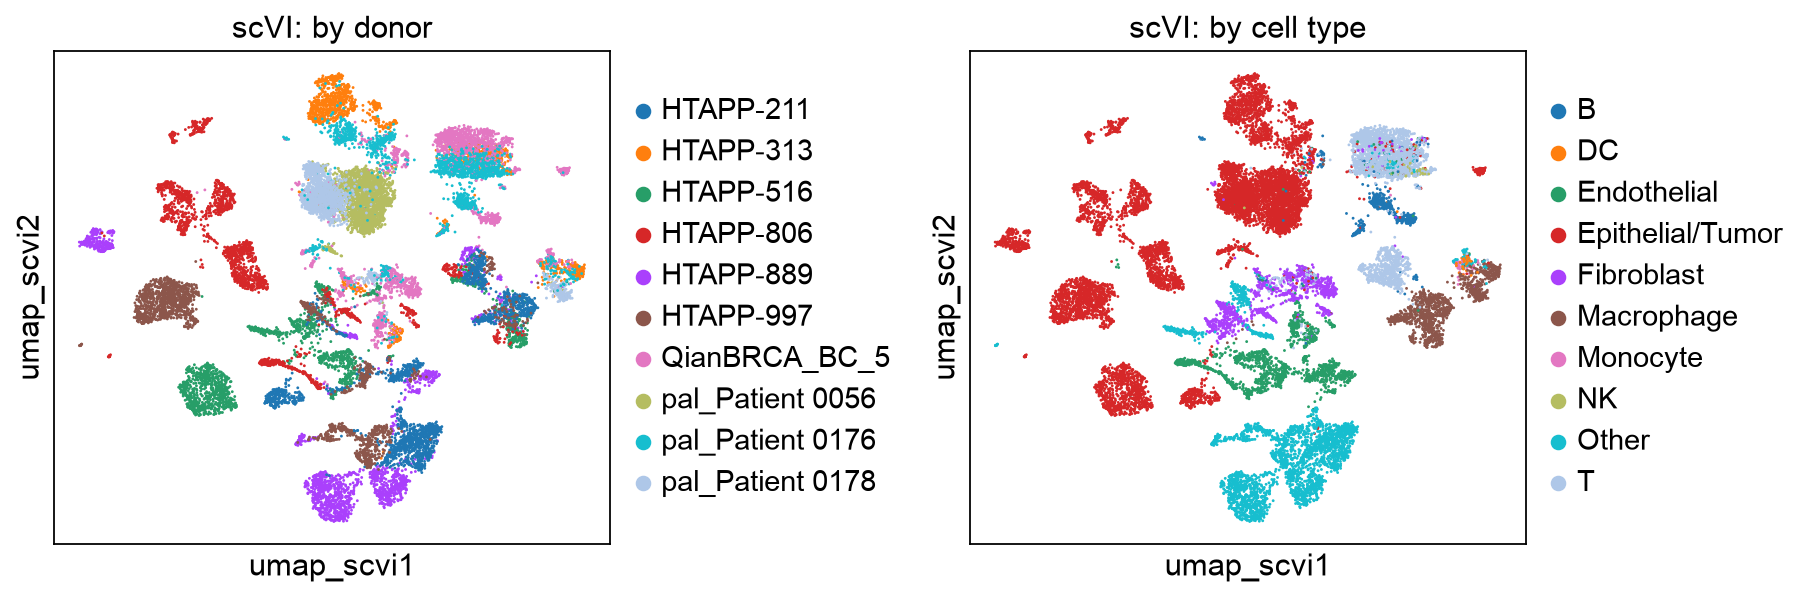

In [8]:
# TODO: plot the scVI UMAP colored by donor and by cell type. Did the donors mix?
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5,
                title=["scVI: by donor", "scVI: by cell type"])

## 1.5 · Harmony, a fair baseline  *(provided)*

In [9]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-23 11:23:45,000 - harmonypy - INFO - Running Harmony


2026-11-23 11:23:45,000 - harmonypy - INFO -   Parameters:


2026-11-23 11:23:45,000 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-23 11:23:45,000 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-23 11:23:45,001 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-23 11:23:45,001 - harmonypy - INFO -     epsilon_harmony: 0.01


... (19 outputs left out)

2026-11-23 11:23:45,172 - harmonypy - INFO - Iteration 9 of 10


2026-11-23 11:23:45,188 - harmonypy - INFO - Iteration 10 of 10


2026-11-23 11:23:45,205 - harmonypy - INFO - Stopped before convergence


Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

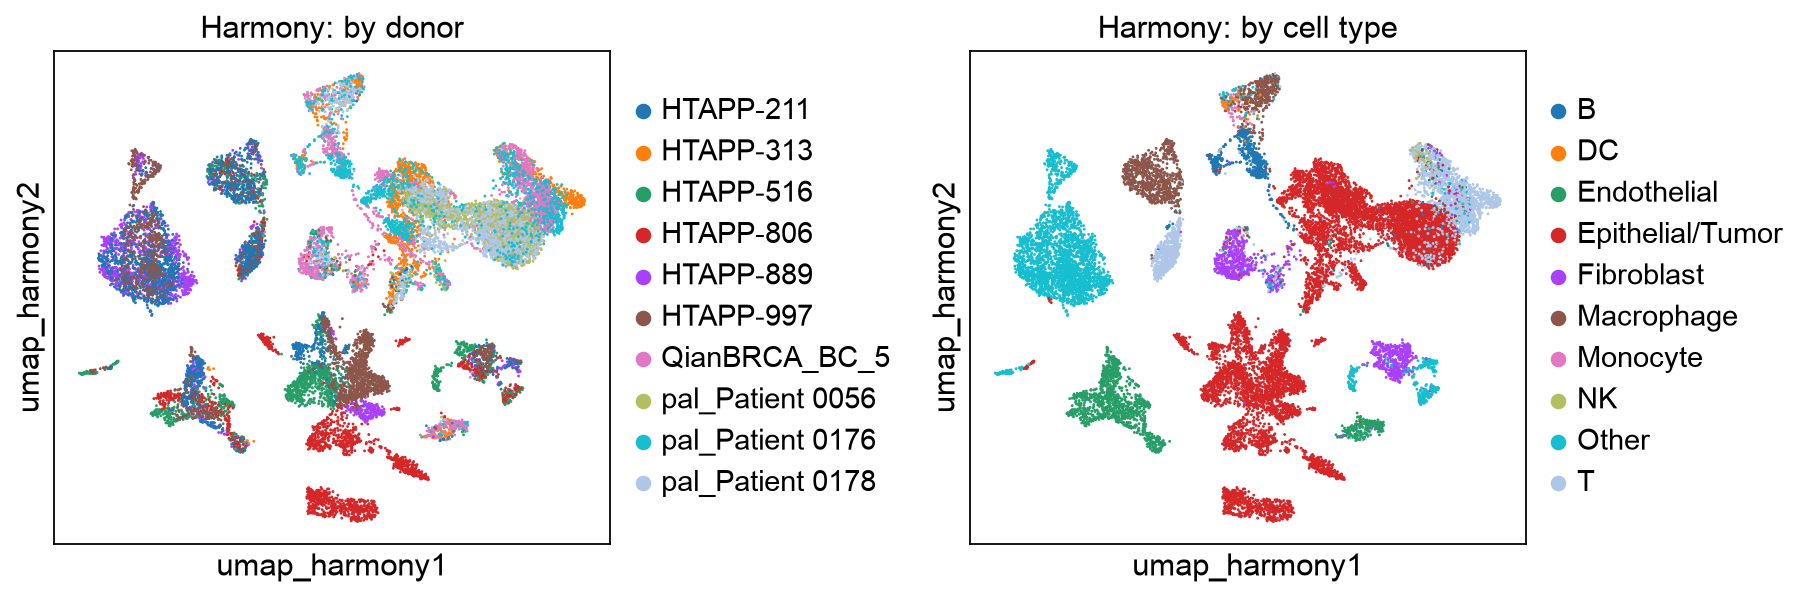

        method  batch silhouette (lower = better mixing)  cell-type silhouette (higher = better biology)
No integration                                     0.095                                          -0.016
       Harmony                                    -0.082                                           0.006
          scVI                                    -0.028                                           0.035


In [10]:
from sklearn.metrics import silhouette_score
# TODO: for each embedding, score batch mixing (by donor_id, lower is better)
#       and biology preservation (by cell_type_broad, higher is better).

# First plot the Harmony embedding so all three methods can also be compared by eye.
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony")
sc.tl.umap(adata)
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="umap_harmony", color=["donor_id", "cell_type_broad"], wspace=0.5,
                title=["Harmony: by donor", "Harmony: by cell type"])

idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
rows = []
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    rows.append({"method": name,
                 "batch silhouette (lower = better mixing)": round(batch, 3),
                 "cell-type silhouette (higher = better biology)": round(bio, 3)})
scores = pd.DataFrame(rows)
print(scores.to_string(index=False))

**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

| Method | Batch silhouette (lower = better) | Cell-type silhouette (higher = better) |
|---|---|---|
| No integration | 0.095 | −0.016 |
| Harmony | **−0.082** | 0.006 |
| scVI | −0.028 | **0.035** |

Both methods beat no integration on both scores. **Harmony mixes donors best** and **scVI preserves cell types best**. I would use **scVI** for the downstream map, because the question is *which cell types* express the target, and that depends most on keeping cell types apart. Most of scVI's weaker mixing is in the tumor cells, which stay grouped by patient; that is expected, since each patient's tumor is genetically distinct. The immune and stromal cells, which should mix, do mix.

The expensive method does **not** clearly beat the simple one. The cell-type scores are all close to zero (the "Other" group is a mix of liver and muscle cells from metastasis biopsies), the gaps are small, and Harmony is better on mixing. scVI also ran on CPU for 60 epochs instead of 200, so it was under-trained. Harmony, at a fraction of the cost, would be an equally defensible choice.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

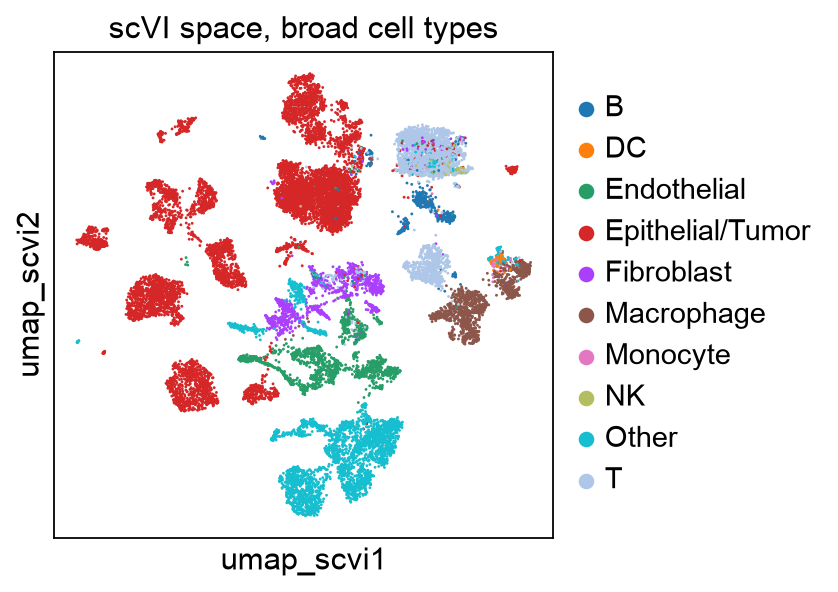

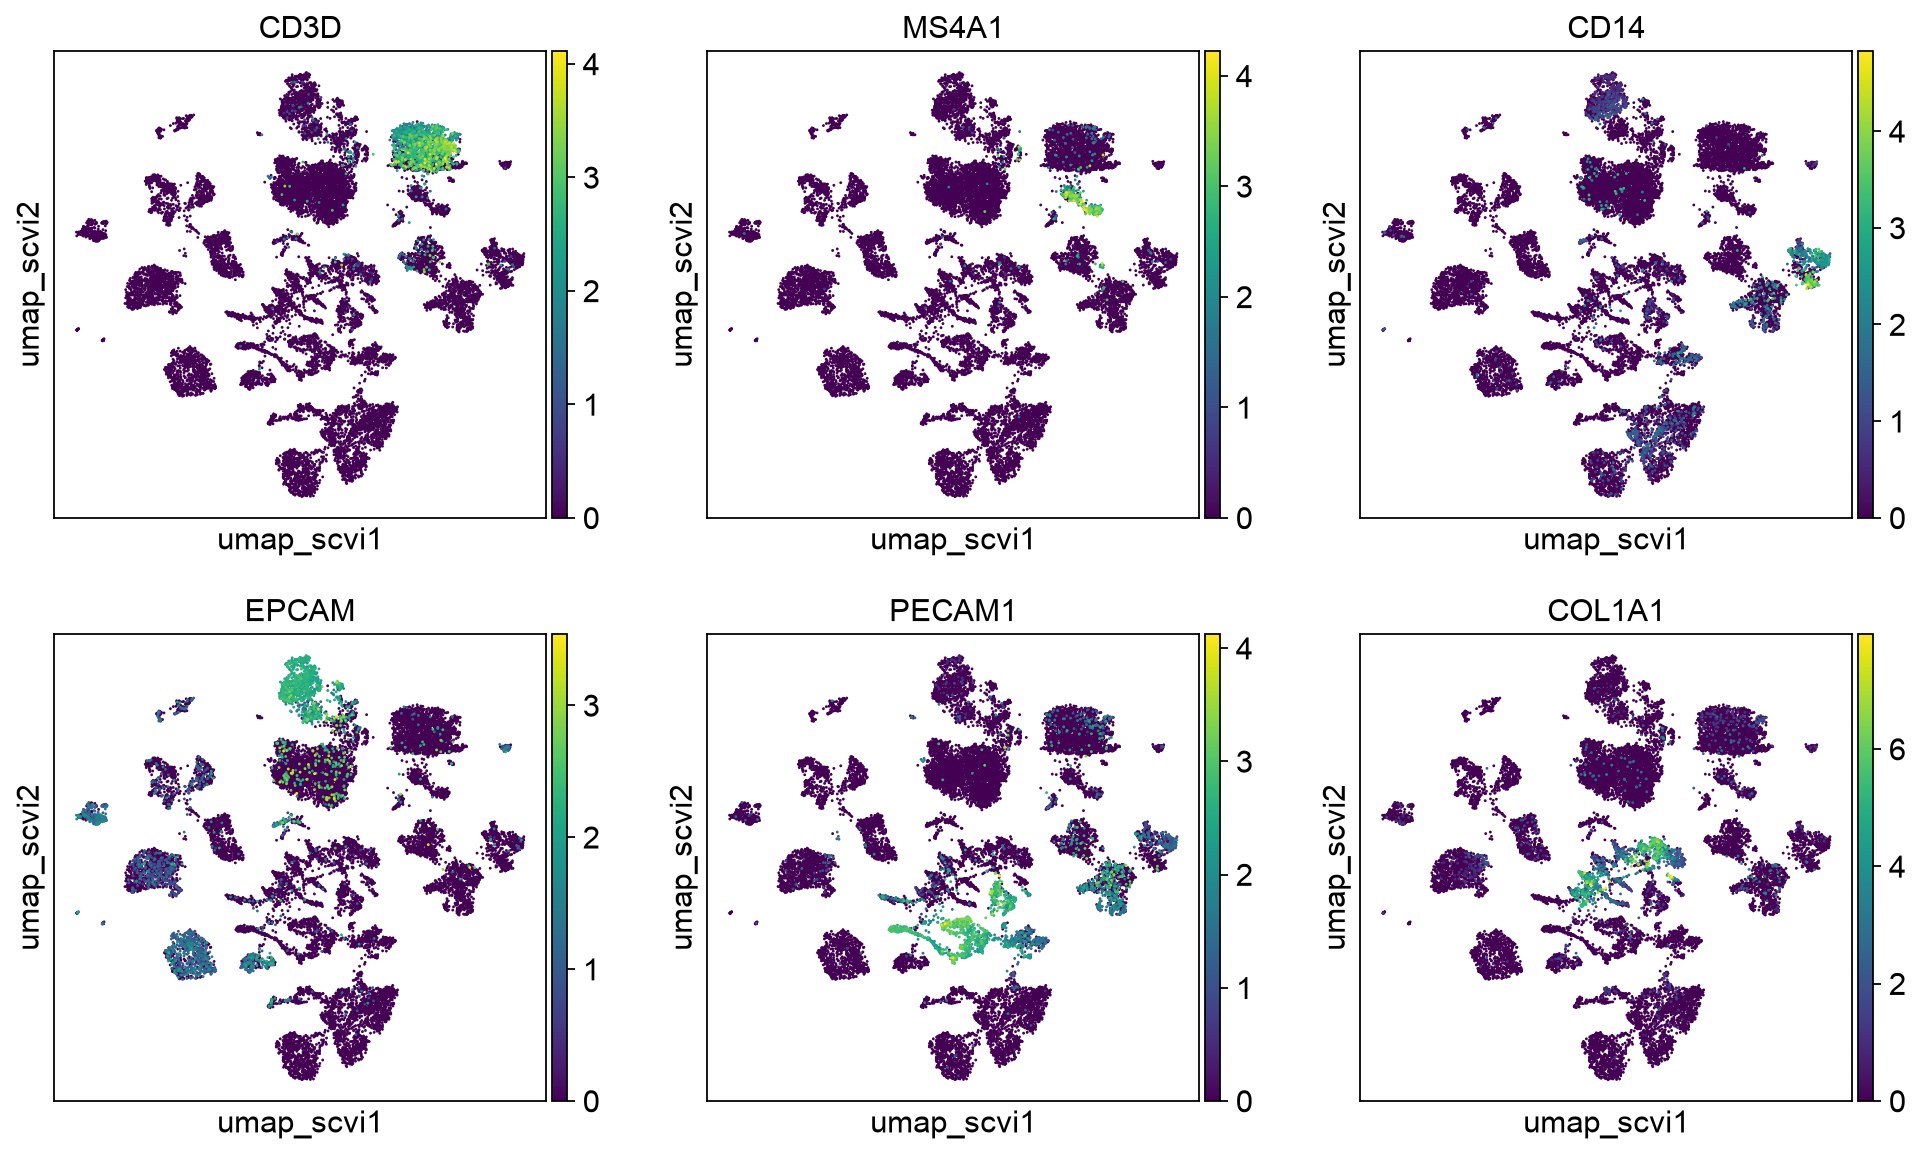

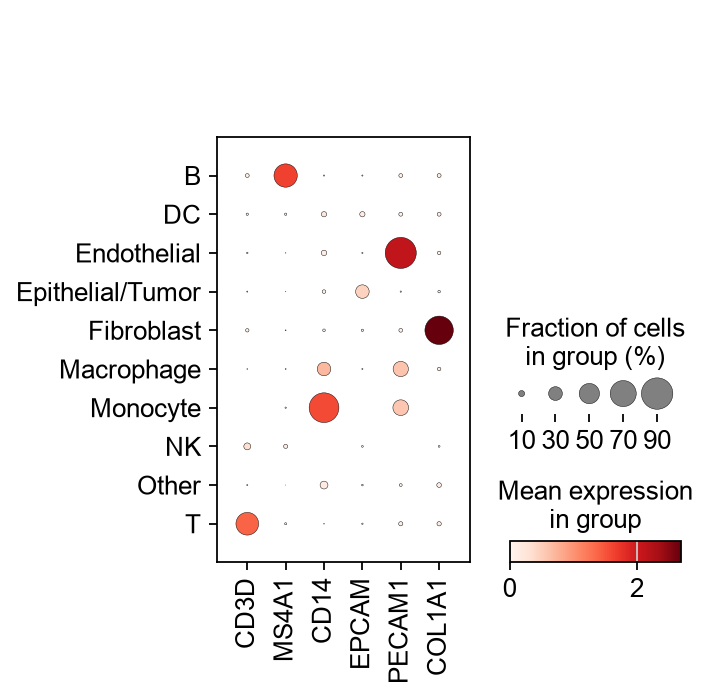

In [11]:
# TODO: plot the scVI UMAP colored by cell_type_broad, and by canonical markers.
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad", title="scVI space, broad cell types")
markers = [g for g in ["CD3D","MS4A1","CD14","EPCAM","PECAM1","COL1A1"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)

# Marker check as numbers: each marker should be highest in its own cell type
sc.pl.dotplot(adata, markers, groupby="cell_type_broad", use_raw=True)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

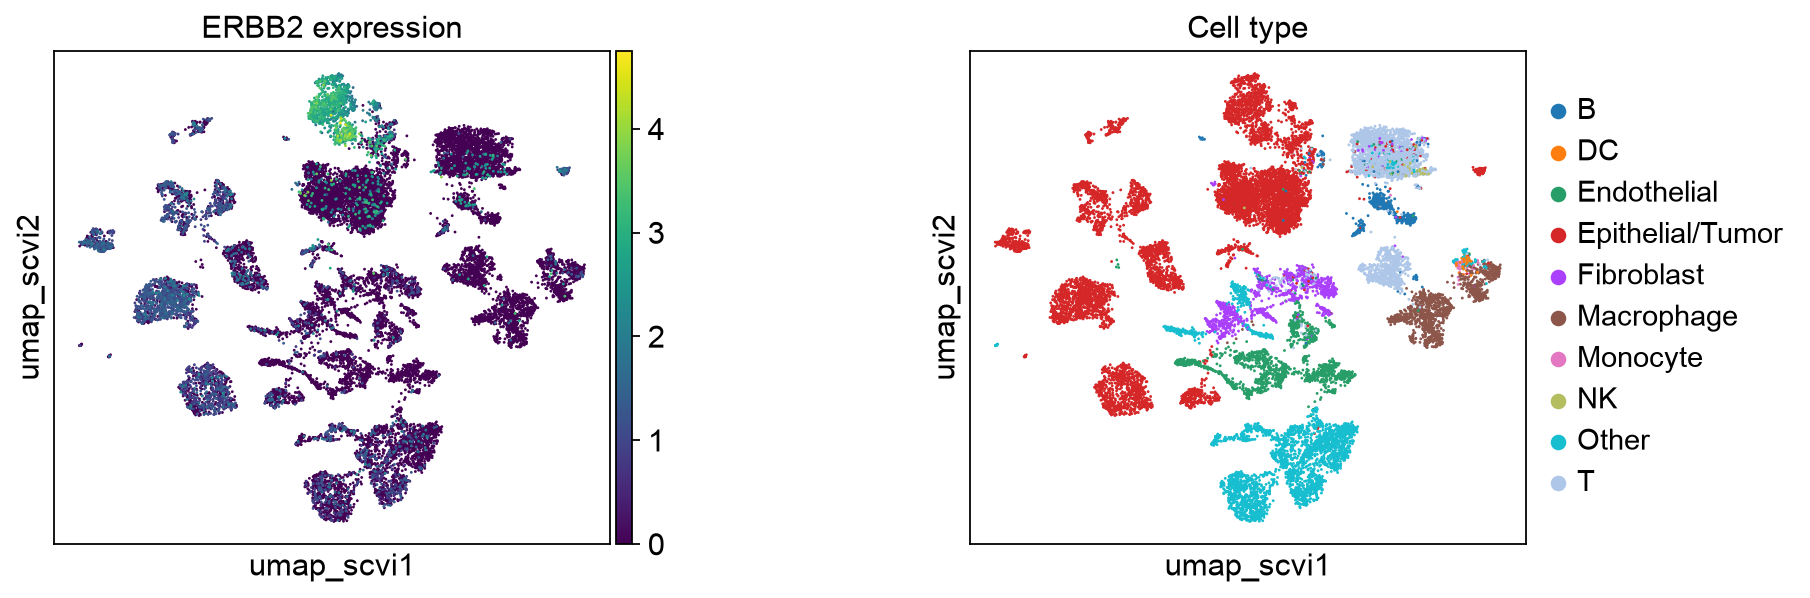

                  n_cells  mean_log_expr  frac_expressing
type                                                     
Epithelial/Tumor     8678          0.633            0.364
NK                     50          0.258            0.100
DC                     36          0.217            0.139
Other                2976          0.192            0.171
B                     529          0.134            0.072
Fibroblast           1072          0.112            0.096
T                    2354          0.056            0.025
Macrophage           1189          0.048            0.030
Endothelial          1431          0.042            0.038
Monocyte               73          0.000            0.000


In [12]:
TARGET = "ERBB2"   # TODO: choose your target: ERBB2, ESR1, EPCAM, MKI67, PTPRC, CD68, CD3D, or your Part I gene
# TODO: plot TARGET on the scVI UMAP.
sc.pl.embedding(adata, basis="umap_scvi", color=[TARGET, "cell_type_broad"], use_raw=True, wspace=0.5,
                title=[f"{TARGET} expression", "Cell type"])

# Which cell types carry it: mean expression and fraction of cells expressing, per broad type
expr = adata.raw[:, TARGET].X
expr = np.asarray(expr.todense()).ravel() if hasattr(expr, "todense") else np.asarray(expr).ravel()
tbl = (pd.DataFrame({"type": adata.obs["cell_type_broad"].values, "expr": expr})
         .groupby("type", observed=True)["expr"]
         .agg(n_cells="size", mean_log_expr="mean", frac_expressing=lambda x: (x > 0).mean())
         .sort_values("mean_log_expr", ascending=False).round(3))
print(tbl.to_string())

**TODO (interpretation):** Which cell type(s) express your target? 

**ERBB2 is expressed by the Epithelial/Tumor cells.** Their mean log-expression is 0.63 and 36% of them express it. Every other type is at or below 0.26, and only 2.5% of T cells, 3% of macrophages and 4% of endothelial cells show it, which is consistent with background RNA. On the UMAP the signal is confined to tumor clusters.

Expression is strongly **patient-dependent**. ERBB2 is detected in 93% of HTAPP-313's tumor cells and 66% of pal_Patient 0176's, but in only 3–5% of pal_Patient 0056's and 0178's. That is the HER2-high vs HER2-low split that decides HER2 therapy in the clinic. Caveat: those two low donors are also the most shallowly sequenced, so part of their low signal may be dropout.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [13]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/var/folders/t8/b8x5dzd135zgwb8p4127n5lw0000gn/T/ipykernel_20726/520941202.py:1: FutureWarning: Use `squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/scanpy/datasets/_datasets.py:555: FutureWarning: Use `squidpy.read.visium` instead.
  return read_visium(sample_dir, source_image_path=source_image_path)


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spots x genes: (3798, 36601)


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## 2.2 · Pipeline and clustering  *(provided)*

In [14]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/var/folders/t8/b8x5dzd135zgwb8p4127n5lw0000gn/T/ipykernel_20726/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

         n_spots  EPCAM  KRT8  KRT18  ERBB2  COL1A1  COL1A2   DCN   LUM  PTPRC  CD3D  MS4A1  CD68  IGKC
cluster                                                                                                
0            725   0.66  3.72   3.36   1.22    2.34    2.37  1.19  1.20   0.44  0.17   0.08  0.66  4.20
1            695   0.52  3.37   2.97   0.98    2.85    2.82  1.87  1.89   0.67  0.34   0.19  0.96  4.53
2            467   0.80  4.33   3.88   1.35    2.45    2.31  0.88  1.24   0.24  0.11   0.02  0.57  2.87
3            412   0.93  3.74   3.33   1.38    1.78    1.67  0.71  0.87   0.24  0.12   0.04  0.53  3.01
4            405   1.02  4.23   3.74   1.64    2.08    1.96  0.80  1.00   0.21  0.08   0.02  0.58  2.92
5            373   1.04  3.68   3.40   1.65    1.73    1.60  0.71  0.90   0.40  0.20   0.04  0.62  2.98
6            358   0.99  3.47   3.20   1.31    1.53    1.51  0.56  0.67   0.15  0.05   0.03  0.42  2.93
7            202   0.83  3.58   3.25   1.41    2.07    2.05  1.0

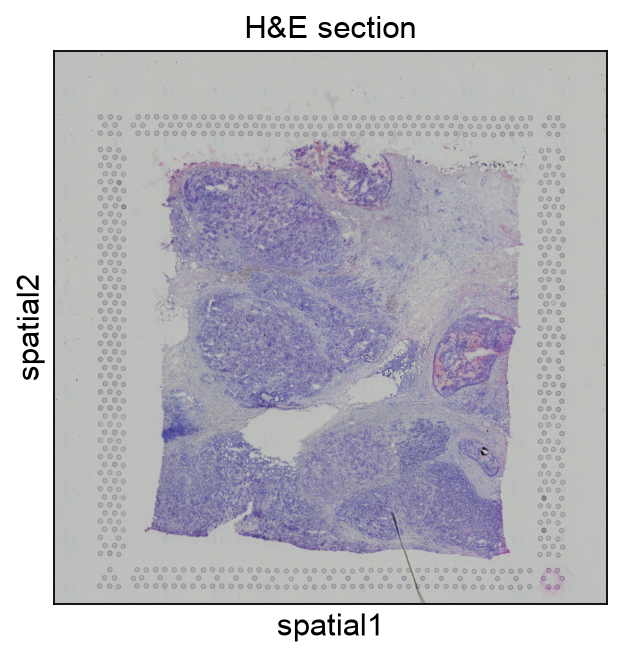

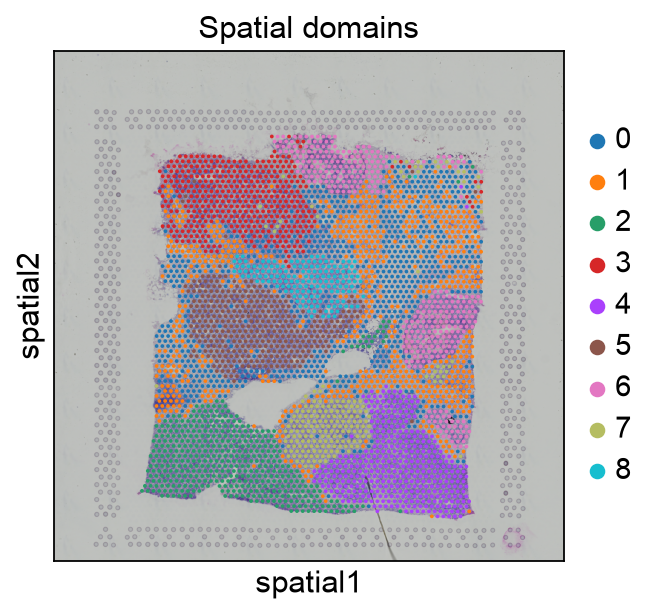

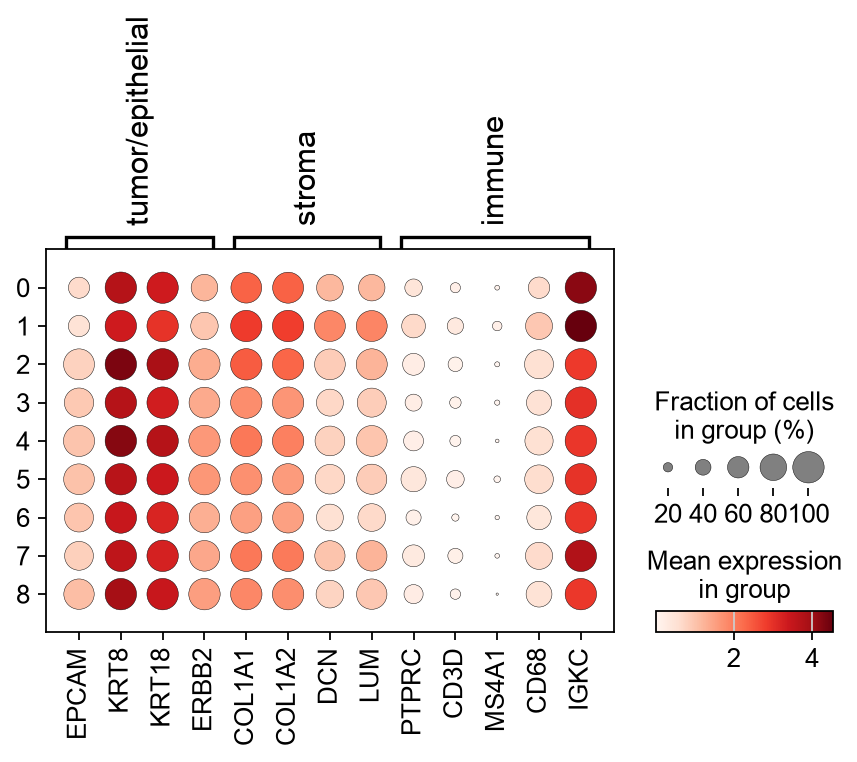

In [15]:
# TODO: plot the clusters on the tissue image.
sq.pl.spatial_scatter(spatial, title="H&E section")                     # the tissue alone
sq.pl.spatial_scatter(spatial, color="cluster", title="Spatial domains")  # domains on the tissue

# Read each domain with compartment markers (mean log-expression per domain)
compartments = {"tumor/epithelial": ["EPCAM", "KRT8", "KRT18", "ERBB2"],
                "stroma": ["COL1A1", "COL1A2", "DCN", "LUM"],
                "immune": ["PTPRC", "CD3D", "MS4A1", "CD68", "IGKC"]}
genes = [g for gs in compartments.values() for g in gs if g in spatial.raw.var_names]
X = spatial.raw[:, genes].X
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
dom = pd.DataFrame(X, columns=genes, index=spatial.obs_names).groupby(spatial.obs["cluster"], observed=True).mean()
dom.insert(0, "n_spots", spatial.obs["cluster"].value_counts().sort_index())
print(dom.round(2).to_string())
sc.pl.dotplot(spatial, compartments, groupby="cluster", use_raw=True)

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

Yes. The nine domains form recognizable architecture, even though the clustering never saw spot positions:
- **Domains 2–8 are tumor nests.** They are compact, separate patches with the highest epithelial/tumor markers (EPCAM 0.80–1.10, ERBB2 1.31–1.65) and the lowest stroma markers (DCN 0.56–1.00).
- **Domains 0 and 1 are the stroma between the nests, with immune cells mixed in.** Together they form the connecting network, with the highest stroma markers (COL1A1 2.34–2.85, DCN/LUM 1.19–1.89) and the highest immune markers (PTPRC 0.44–0.67, CD68 0.66–0.96, IGKC 4.20–4.53). Domain 1 is the most stromal and immune-rich.

Keratins (KRT8/18) are high in every domain because each 55 µm spot mixes several cells. Each nest being its own domain suggests distinct tumor subpopulations; for example, CRISP3 (below) marks only the lower-right nests.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [16]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/t8/b8x5dzd135zgwb8p4127n5lw0000gn/T/ipykernel_20726/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


               I  pval_norm_fdr_bh
MGP     0.868504               0.0
MALAT1  0.762550               0.0
CRISP3  0.726334               0.0
CPB1    0.711023               0.0
IGHG3   0.703817               0.0
IGLC2   0.700306               0.0
IGKC    0.680696               0.0
ALB     0.667866               0.0
IGHG1   0.635266               0.0
IGHG4   0.631525               0.0

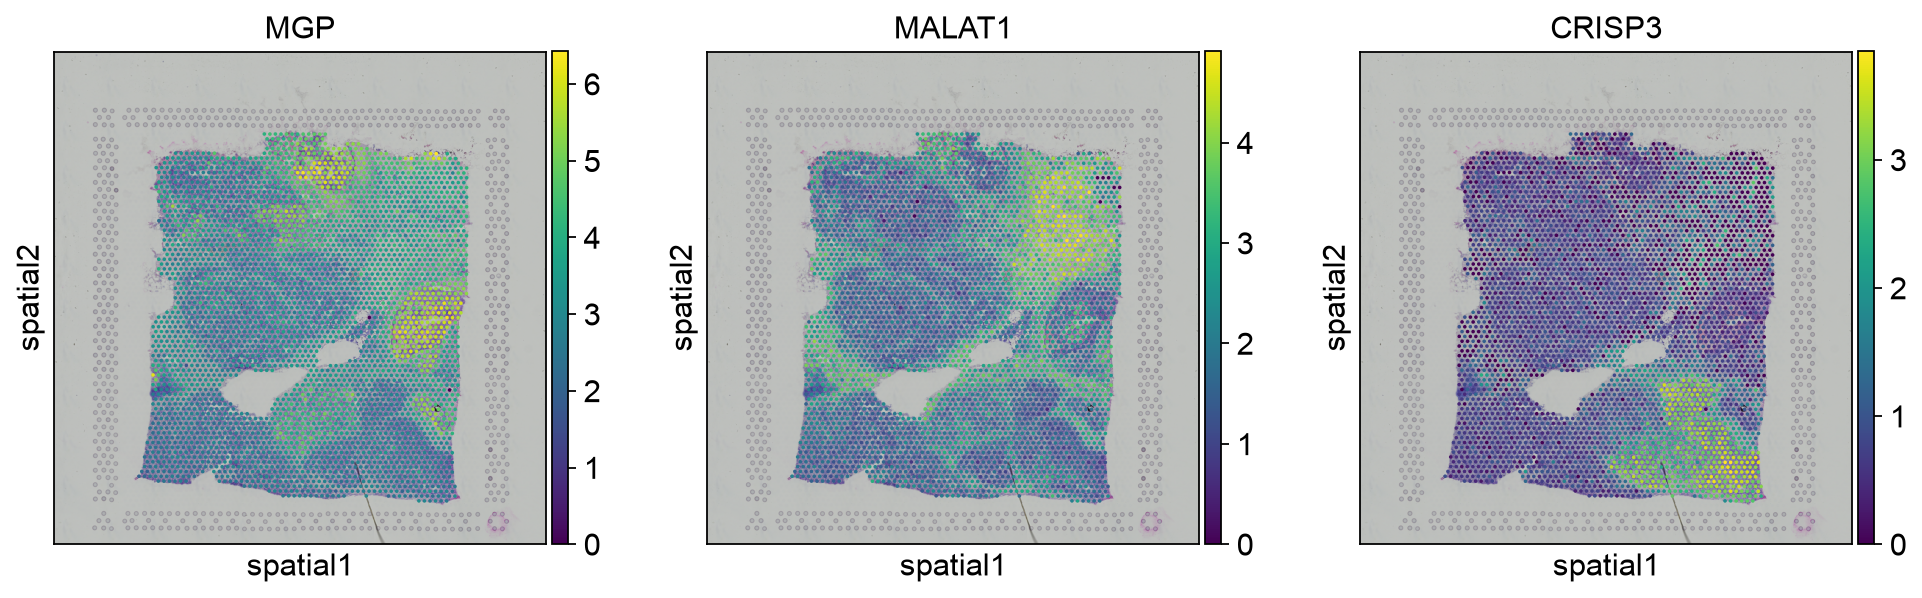

In [17]:
# TODO: compute Moran's I, print the top spatially variable genes, and plot 2-3 on the tissue.
sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(10)
print(top[["I", "pval_norm_fdr_bh"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist(), ncols=3)

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


      0     1     2     3     4     5     6     7     8
0  51.0   8.4 -22.4 -16.8 -21.2 -11.7 -15.7  -9.0  -7.7
1   8.4  55.0 -21.1 -18.4 -20.2 -17.3 -17.6  -9.0  -9.7
2 -22.4 -21.1  94.9 -18.5 -17.3 -17.1 -17.2 -12.2 -11.2
3 -16.8 -18.4 -18.5  87.0 -17.4 -15.8 -13.2  -7.7 -10.2
4 -21.2 -20.2 -17.3 -17.4  93.9 -16.4 -16.4  -9.0 -10.7
5 -11.7 -17.3 -17.1 -15.8 -16.4  86.2 -15.6 -11.0  -4.7
6 -15.7 -17.6 -17.2 -13.2 -16.4 -15.6  87.6  -9.6  -9.8
7  -9.0  -9.0 -12.2  -7.7  -9.0 -11.0  -9.6  77.0  -7.2
8  -7.7  -9.7 -11.2 -10.2 -10.7  -4.7  -9.8  -7.2  84.9


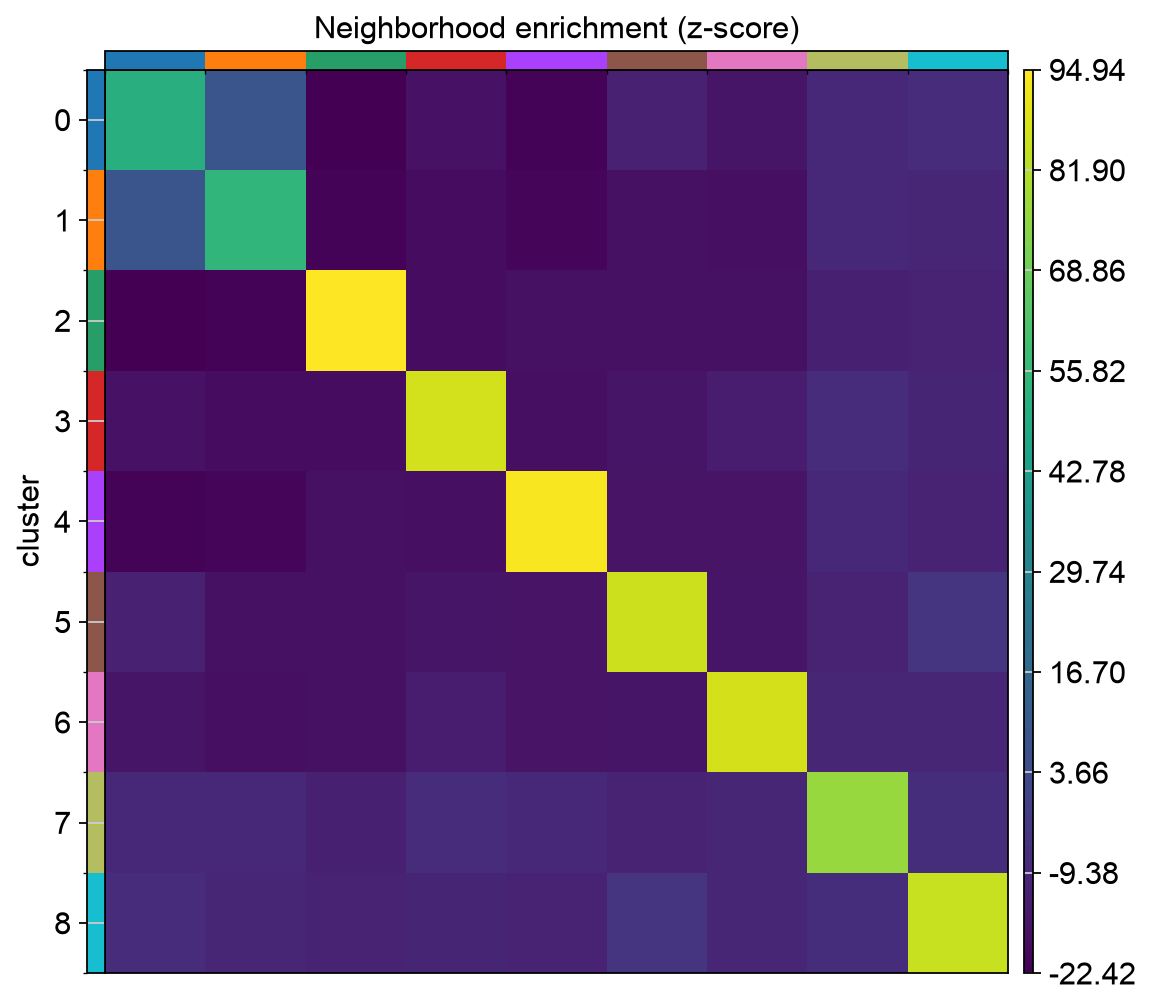

In [18]:
# TODO: run and plot neighborhood enrichment across the clusters.
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster", title="Neighborhood enrichment (z-score)")
z = pd.DataFrame(spatial.uns["cluster_nhood_enrichment"]["zscore"],
                 index=spatial.obs["cluster"].cat.categories, columns=spatial.obs["cluster"].cat.categories)
print(z.round(1).to_string())

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

Every domain is strongly enriched with itself (diagonal z = 51–95), so the domains are spatially compact. The only off-diagonal pair above chance is **0–1 (z = 8.4)**, the two stroma/immune domains forming one connected network.

Every tumor-nest–stroma pair is **below** chance (z = −4.7 to −22.4). So at domain level there is **no tumor–immune interface enriched beyond chance**. Immune cells sit in the stromal tracts *around* the nests rather than mixing into them, a pattern resembling immune exclusion. The least-depleted contacts are between the stroma (0/1) and nests 7 and 8 (z −7.7 to −9.7), which are the most likely places for direct contact. Caveat: with large, compact domains, off-diagonal z-scores tend to be negative, and 55 µm spots cannot resolve single-cell contacts at a boundary.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

          mean  frac_spots_expressing
cluster                              
5        1.650                  0.995
4        1.637                  0.995
8        1.534                  1.000
7        1.411                  0.965
3        1.382                  0.973
2        1.355                  0.991
6        1.315                  0.961
0        1.216                  0.803
1        0.980                  0.835


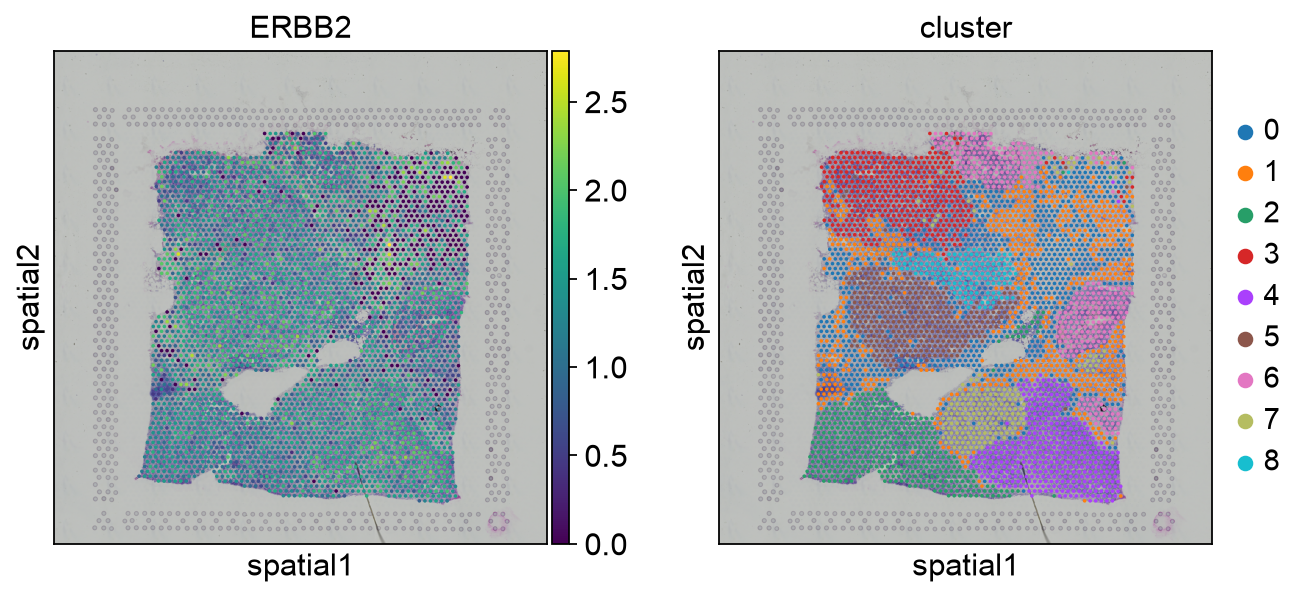

In [19]:
# TODO: plot TARGET on the tissue (if it is present in this section).
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=[TARGET, "cluster"], ncols=2)
    t = spatial.raw[:, TARGET].X
    t = np.asarray(t.todense()).ravel() if hasattr(t, "todense") else np.asarray(t).ravel()
    print(pd.DataFrame({"cluster": spatial.obs["cluster"].values, TARGET: t})
            .groupby("cluster", observed=True)[TARGET].agg(["mean", lambda x: (x > 0).mean()])
            .rename(columns={"<lambda_0>": "frac_spots_expressing"})
            .sort_values("mean", ascending=False).round(3).to_string())
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

**ERBB2 sits in the tumor core, throughout the nests.** It is detected in 96–100% of spots in every tumor domain, highest in nests 5, 4 and 8 (mean 1.53–1.65), and lowest in the stroma/immune domains 0 (mean 1.22, 80% of spots) and 1 (0.98, 84%). It fills each nest fairly evenly instead of concentrating at the invasive margin or in an immune niche. That matches Part 1, where ERBB2 belongs to the tumor cells.

The lower but non-zero stromal signal is expected, because stroma spots at nest edges also capture tumor cells. Clinically, uniform HER2 across the nests is favorable for HER2-directed antibodies or antibody–drug conjugates. But because the nests are walled off by stroma that keeps immune cells out (2.5), a drug has to get through that stroma to reach the core.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.